## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams.

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [13]:
import pickle

with open('/content/sample_data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()


Plot a histogram of the occurrences of tokens.
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.**

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions?

**Q3.**

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** [To be provided]

**Date:** [To be provided]

Unique tokens: 48691
Tokens appearing once: 0
Most common: [('new', 1365), ('date', 1202), ('get', 1052), ('please', 1022), ('enron', 927), ('like', 923), ('2002', 869), ('would', 806), ('one', 798), ('message', 795)]


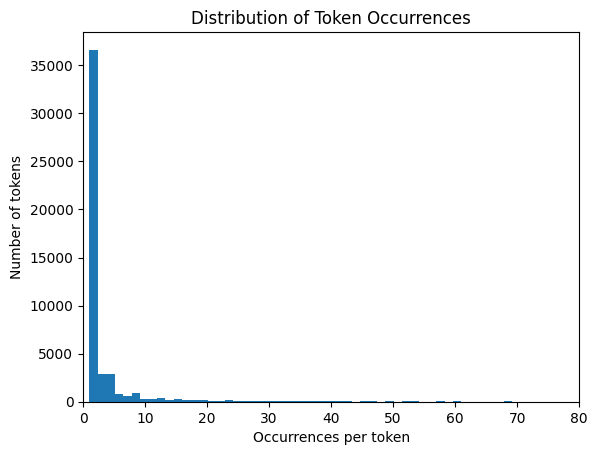

(18634, 2711) {0: 11322, 1: 7312}

Q2 Train R^2: 0.7680301260237321
Q2 Test R^2:  0.6587519780798341
                token      coef      freq    impact
0   background-image: -0.891476  0.064265 -0.057291
1           localized  0.815698  0.054471  0.044432
2          helvetica,  0.717349  0.053331  0.038257
3             thermal  0.706216  0.051251  0.036194
5          transcript  0.578132  0.049104  0.028389
4               aging  0.622411  0.037432  0.023298
7          retrieving -0.527824  0.041994 -0.022165
8                cnet -0.510492  0.040652 -0.020753
9               zdnet -0.503465  0.039377 -0.019825
10             xanaax  0.503086  0.033608  0.016908
13  {text-decoration:  0.449816  0.034480  0.015510
14              form.  0.442778  0.034749  0.015386
16              none; -0.437793  0.033743 -0.014772
11             arial, -0.485267  0.028376 -0.013770
15             rhythm  0.441920  0.030858  0.013637
17             issue: -0.436110  0.030657 -0.013370
22      forward


Q3 Explained variance ratio: [0.0111309  0.00861237]

Q4 Train R^2: 0.7673333826623814
Q4 Test R^2:  0.6597095337756083


In [30]:
import os, pickle
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA

with open('/content/sample_data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
token_count = Counter(all_tokens)
token_freq = token_count.most_common()
counts = [c for _, c in token_freq]


print('Unique tokens:', len(token_freq))
print('Tokens appearing once:', token_freq.count((1)))
print('Most common:', token_freq[:10])

plt.hist(counts, bins=1000)
plt.xlabel('Occurrences per token')
plt.ylabel('Number of tokens')
plt.title('Distribution of Token Occurrences')
plt.xlim(0,80)
plt.show()

# The token occurences are heavily right skewed with a long tail. There is clearly a clustering of infrequent high token count entries,ca




import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

df = pd.read_parquet('/content/sample_data/Phishing_clean.parquet')

# Make sure the target is numeric 0/1 and every feature column is numeric
y = df['Email Type'].astype(int)
X = df.drop(columns=['Email Type'])
X = X.select_dtypes(include=[np.number, bool]).astype(float)   # drops stray text/index cols
print(X.shape, y.value_counts().to_dict())

# 1. 80/20 split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=100
)

# 2. OLS regression
reg = LinearRegression().fit(X_train, y_train)
print('\nQ2 Train R^2:', reg.score(X_train, y_train))
print('Q2 Test R^2: ', reg.score(X_test, y_test))

coefs['freq'] = X_train.mean().values
coefs['impact'] = coefs['coef'] * coefs['freq']
print(coefs.reindex(coefs['impact'].abs().sort_values(ascending=False).index).head(20))

# Q4
# 3. Largest coefficients by absolute value
coefs = pd.DataFrame({'token': X.columns, 'coef': reg.coef_})
coefs = coefs.iloc[coefs['coef'].abs().argsort()[::-1]].reset_index(drop=True)
print('\nTop 20 coefficients by absolute value:')
print(coefs.head(20).to_string())
# Q3:
pca2 = PCA(n_components=2)
Z2 = pca2.fit_transform(X)
pca_df = pd.DataFrame(Z2, columns=['PC1', 'PC2'])
pca_df['Email Type'] = y.values.astype(str)
px.scatter(pca_df, x='PC1', y='PC2', color='Email Type', opacity=0.5,
           title='First Two Principal Components').show()
print('\nQ3 Explained variance ratio:', pca2.explained_variance_ratio_)

pca = PCA(n_components=2610)
Z_train = pca.fit_transform(X_train)
Z_test = pca.transform(X_test)
reg_pca = LinearRegression().fit(Z_train, y_train)
print('\nQ4 Train R^2:', reg_pca.score(Z_train, y_train))
print('Q4 Test R^2: ', reg_pca.score(Z_test, y_test))

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]